In [24]:
print("Program is developed by",u"\u092A\u094D\u0930\u093F\u092F\u093E\u0902\u0936\u0941\u0020\u092E\u093F\u0936\u094D\u0930\u093E")
print("Program is checked by",u"\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947 / \u0936\u094d\u0935\u0947\u0924\u093e \u0935\u093e\u0928\u0916\u0947\u0921\u093c\u0947")

Program is developed by प्रियांशु मिश्रा
Program is checked by वैशाली इंगळे / श्वेता वानखेड़े


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import pairwise_distances
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
import scipy.cluster.hierarchy as sch
from sklearn.cluster import BisectingKMeans
import matplotlib.patches as mpatches
from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import linkage, dendrogram
from matplotlib.lines import Line2D

# Visualization styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
# Load the dataset (replace 'Iris.csv' with your local filename/path if needed)
df = pd.read_csv("Iris.csv")
df.rename(columns={
        "sepal_length": "SepalLengthCm",
        "sepal_width": "SepalWidthCm",
        "petal_length": "PetalLengthCm",
        "petal_width": "PetalWidthCm",
        "species": "Species"
    }, inplace=True)

# Drop identifier column if present
if "Id" in df.columns:
    df.drop(columns=["Id"], inplace=True)

# Separate features and target ground truth
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = df[feature_cols].values
y_true = df["Species"]

# Standardize the features so variables with larger variance don't dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


# K-Means — Elbow Method for Optimal $k$

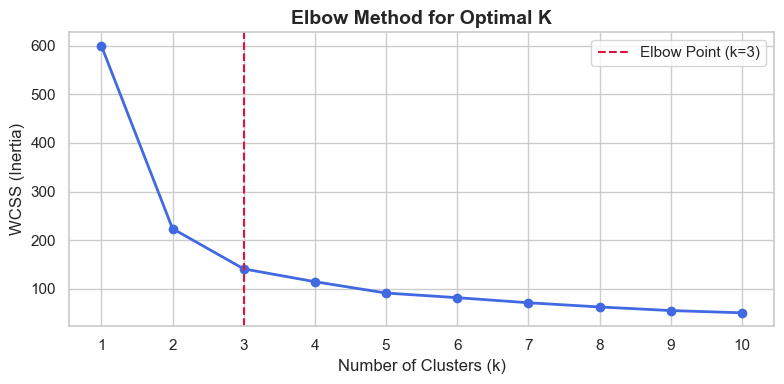

In [4]:
wcss = []  # Within-Cluster Sum of Squares (Inertia)
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, marker="o", color="royalblue", linewidth=2)
plt.title("Elbow Method for Optimal K", fontsize=14, fontweight="bold")
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("WCSS (Inertia)", fontsize=12)
plt.xticks(K_range)
plt.axvline(x=3, color="crimson", linestyle="--", label="Elbow Point (k=3)")
plt.legend()
plt.tight_layout()
plt.show()

# K-Means Clustering & Visualization

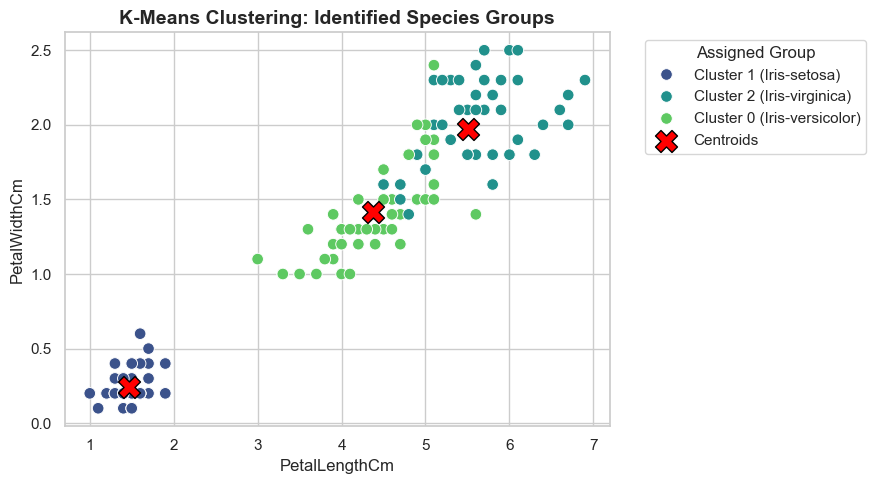

In [6]:
# 1. Fit K-Means with optimal k = 3
kmeans_optimal = KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans_optimal.fit_predict(X_scaled)

# 2. Automatically map cluster numbers (0, 1, 2) to their dominant true species name
cluster_to_species = {}
for cluster_id in range(3):
    dominant_species = df[df["KMeans_Cluster"] == cluster_id]["Species"].mode()[0]
    cluster_to_species[cluster_id] = f"Cluster {cluster_id} ({dominant_species})"

df["KMeans_Species_Predicted"] = df["KMeans_Cluster"].map(cluster_to_species)

# 3. Plot Petal Length vs Petal Width with meaningful species labels
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="KMeans_Species_Predicted",
    palette="viridis",
    s=70,
    ax=ax
)

# 4. Unscale and plot cluster centers
centroids = scaler.inverse_transform(kmeans_optimal.cluster_centers_)
ax.scatter(
    centroids[:, 2], centroids[:, 3],
    s=250, c="red", marker="X", edgecolor="black", label="Centroids"
)

plt.title("K-Means Clustering: Identified Species Groups", fontsize=14, fontweight="bold")
plt.legend(title="Assigned Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Hierarchical Clustering — Dendrogram

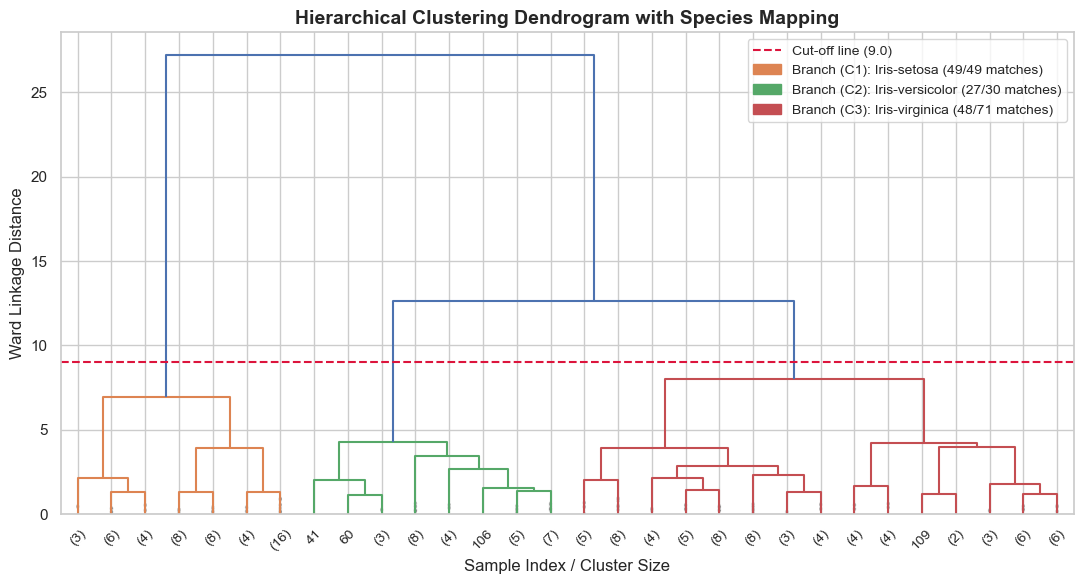

In [8]:
# 1. Compute linkage matrix using Ward's minimum variance method
linked = sch.linkage(X_scaled, method="ward")

# Define cut threshold to yield 3 clusters
cut_threshold = 9.0

# 2. Extract cluster assignments at this cut-off threshold
cluster_ids = fcluster(linked, t=cut_threshold, criterion="distance")
df["Dendro_Cluster"] = cluster_ids

# Map each cluster ID to its majority true species name
branch_species_map = {}
for cid in np.unique(cluster_ids):
    dominant = df[df["Dendro_Cluster"] == cid]["Species"].mode()[0]
    count = (df[df["Dendro_Cluster"] == cid]["Species"] == dominant).sum()
    total = len(df[df["Dendro_Cluster"] == cid])
    branch_species_map[cid] = f"{dominant} ({count}/{total} matches)"

# 3. Plot Dendrogram with color thresholding enabled
plt.figure(figsize=(11, 6))
dendro_dict = sch.dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=cut_threshold  # Colors branches below this threshold
)

# Draw horizontal cut line
plt.axhline(y=cut_threshold, color="crimson", linestyle="--", linewidth=1.5, label=f"Cut threshold ({cut_threshold})")

# 4. Extract unique branch colors (excluding root blue/gray) and map them to the species
unique_colors = list(dict.fromkeys([c for c in dendro_dict["color_list"] if c != "C0"]))

# Build dynamic legend handles for the branch colors
legend_handles = [plt.Line2D([0], [0], color="crimson", linestyle="--", label=f"Cut-off line ({cut_threshold})")]
for idx, color in enumerate(unique_colors):
    cluster_num = idx + 1
    species_label = branch_species_map.get(cluster_num, f"Cluster {cluster_num}")
    patch = mpatches.Patch(color=color, label=f"Branch ({color}): {species_label}")
    legend_handles.append(patch)

plt.title("Hierarchical Clustering Dendrogram with Species Mapping", fontsize=14, fontweight="bold")
plt.xlabel("Sample Index / Cluster Size", fontsize=12)
plt.ylabel("Ward Linkage Distance", fontsize=12)
plt.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Agglomerative Clustering & Visualization

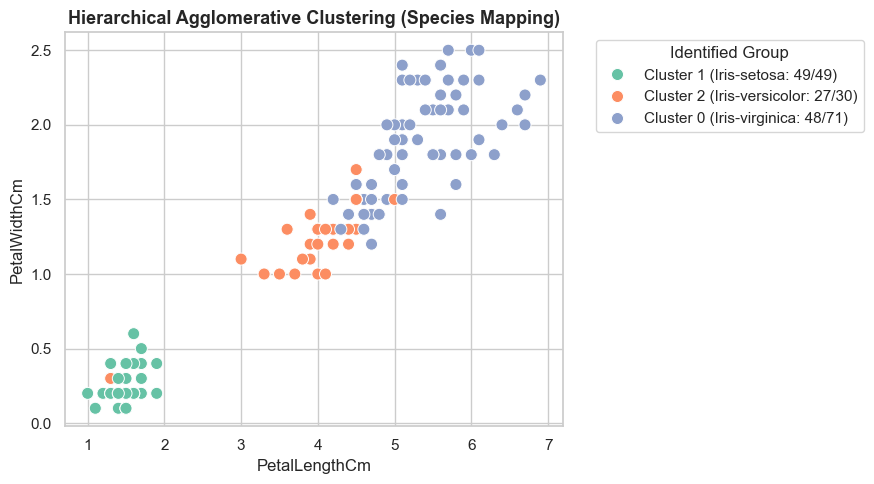

In [10]:
# 1. Fit Agglomerative Clustering with 3 clusters
agg_cluster = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
df["Agg_Cluster"] = agg_cluster.fit_predict(X_scaled)

# 2. Map cluster numbers (0, 1, 2) to their dominant true species name and purity
agg_species_map = {}
for cluster_id in np.unique(df["Agg_Cluster"]):
    cluster_subset = df[df["Agg_Cluster"] == cluster_id]
    dominant_species = cluster_subset["Species"].mode()[0]
    matches = (cluster_subset["Species"] == dominant_species).sum()
    total = len(cluster_subset)
    agg_species_map[cluster_id] = f"Cluster {cluster_id} ({dominant_species}: {matches}/{total})"

df["Agg_Species_Predicted"] = df["Agg_Cluster"].map(agg_species_map)

# 3. Plot Petal Length vs Petal Width with explicit species labels
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Agg_Species_Predicted",
    palette="Set2",
    s=75
)

plt.title("Hierarchical Agglomerative Clustering (Species Mapping)", fontsize=13, fontweight="bold")
plt.legend(title="Identified Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Divisive Hierarchical Clustering

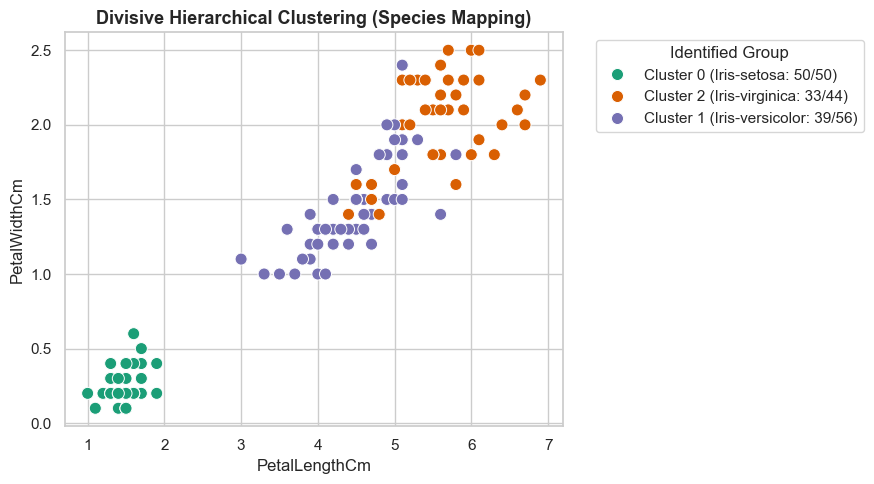

In [12]:
# 1. Fit Divisive (Top-Down) Hierarchical Clustering with 3 clusters
divisive_cluster = BisectingKMeans(n_clusters=3, random_state=42, bisecting_strategy="biggest_inertia")
df["Divisive_Cluster"] = divisive_cluster.fit_predict(X_scaled)

# 2. Map cluster numbers (0, 1, 2) to their dominant true species name and purity
divisive_species_map = {}
for cluster_id in np.unique(df["Divisive_Cluster"]):
    cluster_subset = df[df["Divisive_Cluster"] == cluster_id]
    dominant_species = cluster_subset["Species"].mode()[0]
    matches = (cluster_subset["Species"] == dominant_species).sum()
    total = len(cluster_subset)
    divisive_species_map[cluster_id] = f"Cluster {cluster_id} ({dominant_species}: {matches}/{total})"

df["Divisive_Species_Predicted"] = df["Divisive_Cluster"].map(divisive_species_map)

# 3. Visualize Divisive Clusters with explicit species labels
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Divisive_Species_Predicted",
    palette="Dark2",
    s=75
)

plt.title("Divisive Hierarchical Clustering (Species Mapping)", fontsize=13, fontweight="bold")
plt.legend(title="Identified Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

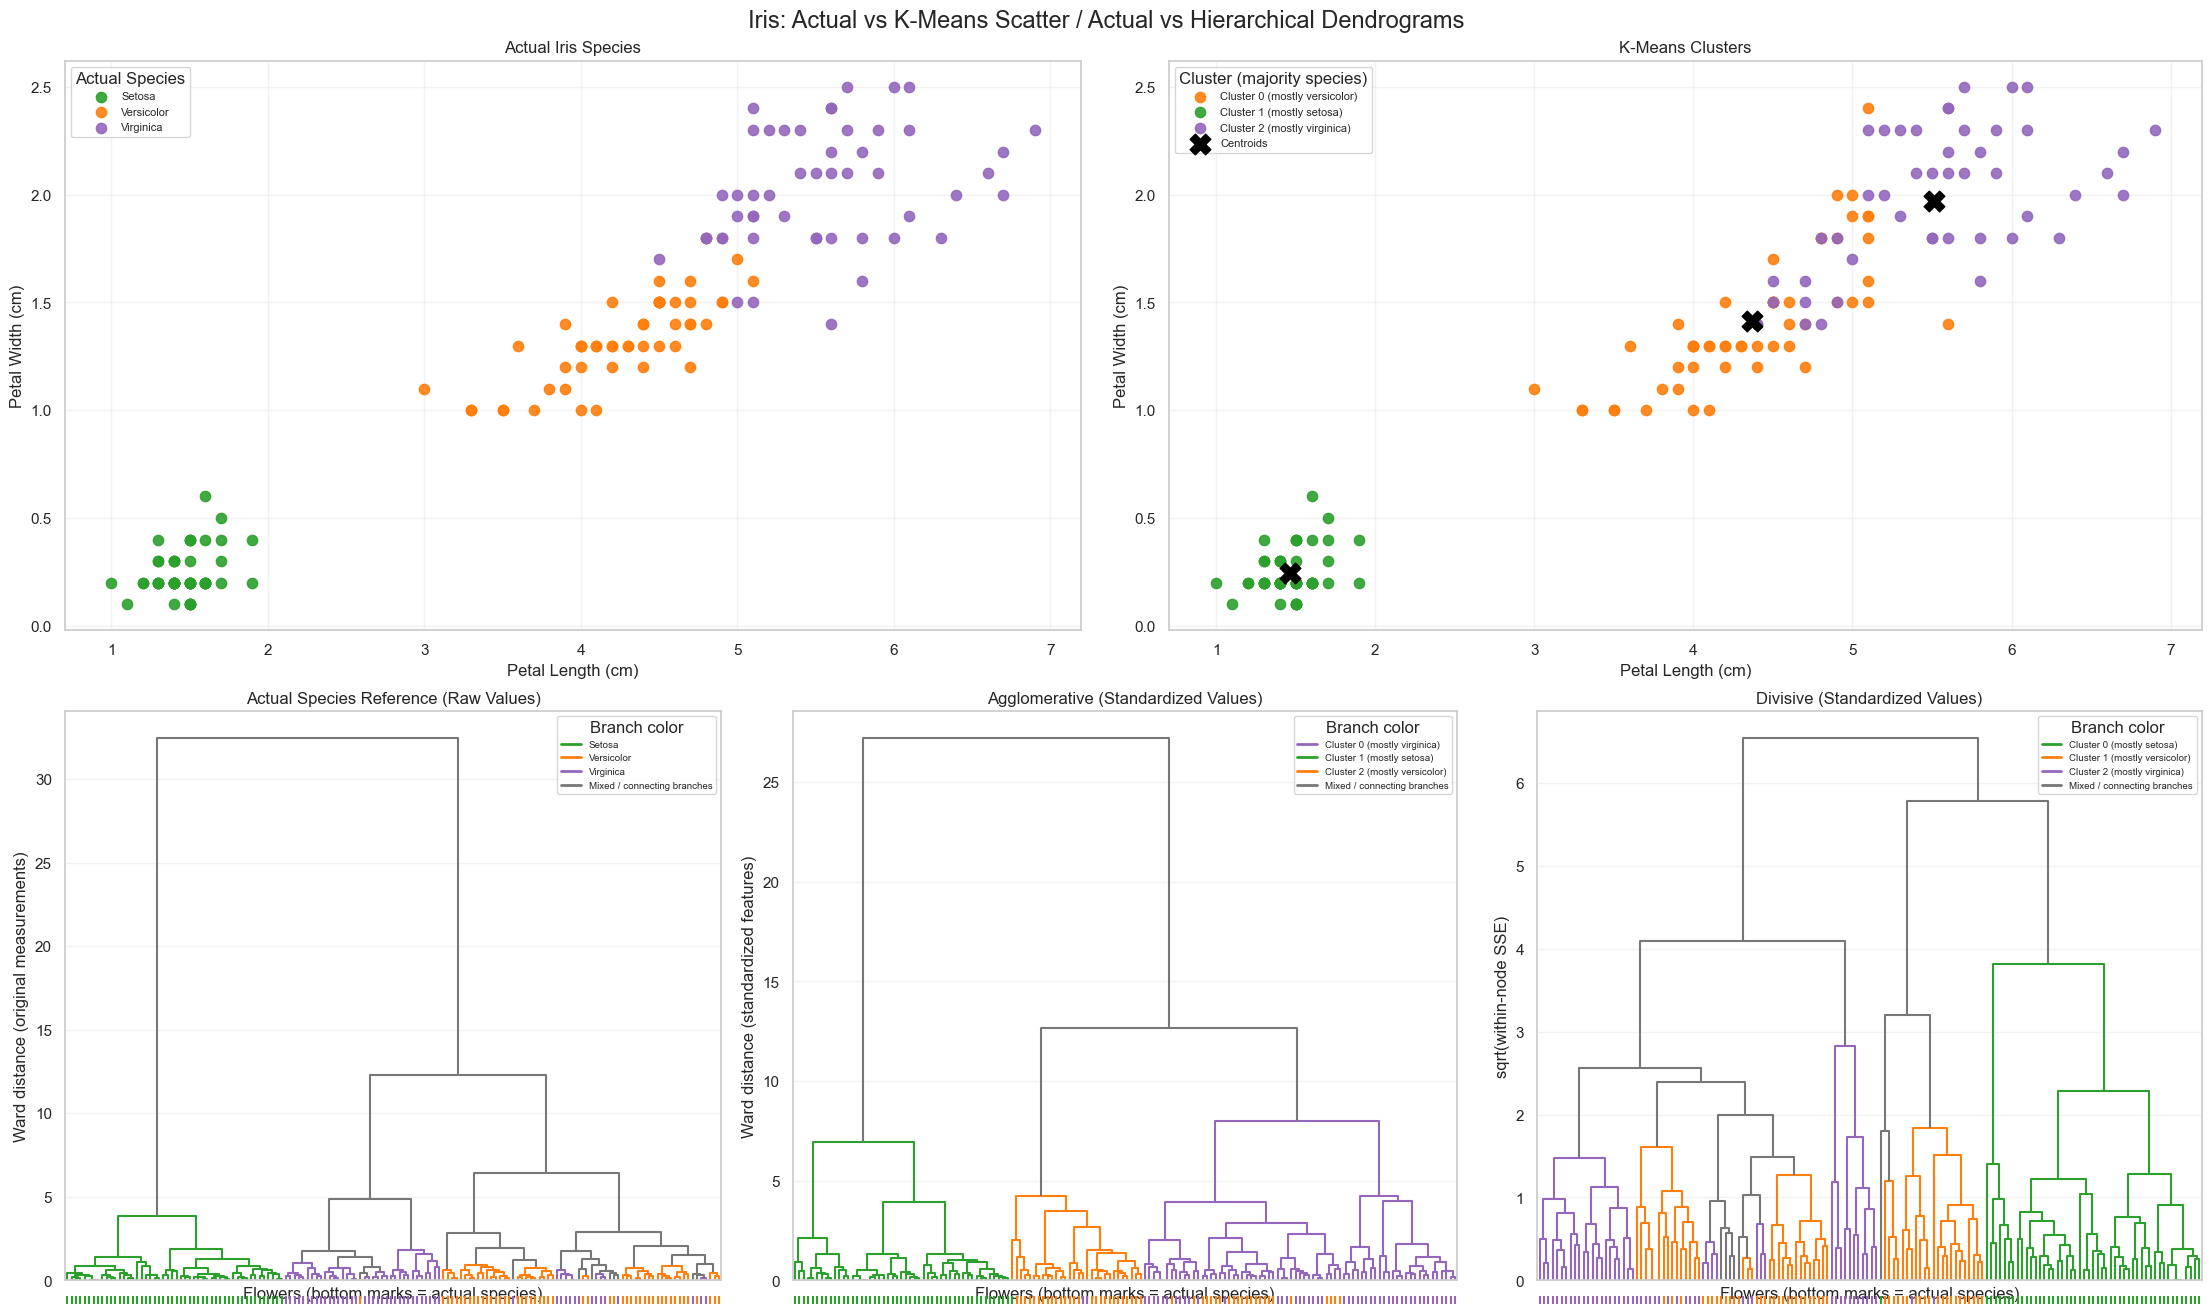

In [13]:
# 1. Color Palette Dictionary
SPECIES_COLORS = {
    'Iris-setosa': '#2ca02c',      # Green
    'Iris-versicolor': '#ff7f0e',  # Orange
    'Iris-virginica': '#9467bd'   # Purple
}

# 2. Fit models & prepare linkages if not already fitted
if 'KMeans_Cluster' not in df.columns:
    km_obj = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
    df['KMeans_Cluster'] = km_obj.labels_
    centers_original = scaler.inverse_transform(km_obj.cluster_centers_)
else:
    km_obj = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
    centers_original = scaler.inverse_transform(km_obj.cluster_centers_)

if 'Agg_Cluster' in df.columns:
    df['Hierarchical_Cluster'] = df['Agg_Cluster']
else:
    df['Hierarchical_Cluster'] = AgglomerativeClustering(n_clusters=3).fit_predict(X_scaled)

if 'Divisive_Cluster' not in df.columns:
    df['Divisive_Cluster'] = BisectingKMeans(n_clusters=3, random_state=42).fit_predict(X_scaled)

# Ensure label columns exist for legends
for col in ['KMeans_Cluster', 'Hierarchical_Cluster', 'Divisive_Cluster']:
    label_map = {}
    for cid in np.unique(df[col]):
        maj_sp = df[df[col] == cid]['Species'].mode()[0].replace('Iris-', '')
        label_map[cid] = f"Cluster {cid} (mostly {maj_sp})"
    df[col + '_Label'] = df[col].map(label_map)

# Precompute linkages
actual_linked = linkage(X, method='ward')
linked = linkage(X_scaled, method='ward')
divisive_linked = linkage(X_scaled, method='complete')

# Helper: Cluster Color Mapping based on majority true species
def get_cluster_colors(data, col):
    colors = {}
    counts = pd.crosstab(data[col], data['Species'])
    for cluster_id, row in counts.iterrows():
        winner = row.idxmax()
        colors[cluster_id] = SPECIES_COLORS.get(winner, '#777777')
    return colors

# Helper: Dendrogram with custom branch colors & bottom actual species tick marks
def plot_custom_dendrogram(ax, matrix, title, col=None, ylabel='Ward distance'):
    n = len(df)
    labels = df['Species'].to_numpy() if col is None else df[col].to_numpy()
    c_map = SPECIES_COLORS if col is None else get_cluster_colors(df, col)
    
    members = {i: [i] for i in range(n)}
    node_colors = {}
    for row_id, row in enumerate(matrix):
        node = n + row_id
        members[node] = members[int(row[0])] + members[int(row[1])]
        distinct_grps = set(labels[members[node]])
        node_colors[node] = c_map[next(iter(distinct_grps))] if len(distinct_grps) == 1 else '#777777'

    tree = dendrogram(matrix, ax=ax, no_labels=True,
                      link_color_func=lambda node_idx: node_colors.get(node_idx, '#777777'))
    
    # Bottom actual species marks (colored ticks)
    leaf_cols = [SPECIES_COLORS[df.iloc[i]['Species']] for i in tree['leaves']]
    ax.scatter(np.arange(n) * 10 + 5, np.full(n, -0.035),
               c=leaf_cols, marker='|', s=35,
               transform=ax.get_xaxis_transform(), clip_on=False)
    
    handles = []
    if col is None:
        for sp, col_hex in SPECIES_COLORS.items():
            handles.append(Line2D([0], [0], color=col_hex, lw=2, label=sp.replace('Iris-', '').title()))
    else:
        for cid in sorted(c_map):
            lbl = df.loc[df[col] == cid, col + '_Label'].iloc[0]
            handles.append(Line2D([0], [0], color=c_map[cid], lw=2, label=lbl))
    handles.append(Line2D([0], [0], color='#777777', lw=2, label='Mixed / connecting branches'))
    
    ax.legend(handles=handles, title='Branch color', fontsize=7, loc='upper right')
    ax.set(title=title, xlabel='Flowers (bottom marks = actual species)', ylabel=ylabel)
    ax.grid(axis='y', alpha=0.25)

# ==============================================================================
# Master Plot: 2 Rows x 6 Grid Units (NO CIRCLES / ELLIPSES)
# ==============================================================================
fig = plt.figure(figsize=(22, 13), constrained_layout=True)
layout = fig.add_gridspec(2, 6)

# [Row 1, Left]: Actual Species Scatter
ax_act = fig.add_subplot(layout[0, :3])
for sp, subset in df.groupby('Species'):
    ax_act.scatter(subset['PetalLengthCm'], subset['PetalWidthCm'],
                   color=SPECIES_COLORS[sp], s=55, alpha=0.9,
                   label=sp.replace('Iris-', '').title())
ax_act.set(title='Actual Iris Species', xlabel='Petal Length (cm)', ylabel='Petal Width (cm)')
ax_act.legend(title='Actual Species', fontsize=8, loc='upper left')
ax_act.grid(alpha=0.25)

# [Row 1, Right]: K-Means Scatter with Centroids
ax_km = fig.add_subplot(layout[0, 3:])
km_cols = get_cluster_colors(df, 'KMeans_Cluster')
for cid, subset in df.groupby('KMeans_Cluster'):
    ax_km.scatter(subset['PetalLengthCm'], subset['PetalWidthCm'],
                  color=km_cols[cid], s=55, alpha=0.9,
                  label=subset['KMeans_Cluster_Label'].iloc[0])
ax_km.scatter(centers_original[:, 2], centers_original[:, 3], marker='X', s=220,
              color='black', label='Centroids', zorder=5)
ax_km.set(title='K-Means Clusters', xlabel='Petal Length (cm)', ylabel='Petal Width (cm)')
ax_km.legend(title='Cluster (majority species)', fontsize=8, loc='upper left')
ax_km.grid(alpha=0.25)

# [Row 2]: 3 Dendrograms
ax_d1 = fig.add_subplot(layout[1, :2])
ax_d2 = fig.add_subplot(layout[1, 2:4])
ax_d3 = fig.add_subplot(layout[1, 4:])

plot_custom_dendrogram(ax_d1, actual_linked, 'Actual Species Reference (Raw Values)',
                       ylabel='Ward distance (original measurements)')
plot_custom_dendrogram(ax_d2, linked, 'Agglomerative (Standardized Values)',
                       col='Hierarchical_Cluster', ylabel='Ward distance (standardized features)')
plot_custom_dendrogram(ax_d3, divisive_linked, 'Divisive (Standardized Values)',
                       col='Divisive_Cluster', ylabel='sqrt(within-node SSE)')

fig.suptitle('Iris: Actual vs K-Means Scatter / Actual vs Hierarchical Dendrograms', fontsize=17)
plt.show()

In [32]:
# Helper Function: Dunn Index calculate karne ke liye
def calculate_dunn_index(X, labels):
    distances = pairwise_distances(X)
    unique_clusters = np.unique(labels)
    
    # 1. Minimum Inter-cluster distance (2 alag clusters ke points ke beech sabse kam distance)
    min_inter_dist = np.inf
    for i in range(len(unique_clusters)):
        for j in range(i + 1, len(unique_clusters)):
            c1_mask = (labels == unique_clusters[i])
            c2_mask = (labels == unique_clusters[j])
            dist = np.min(distances[np.ix_(c1_mask, c2_mask)])
            if dist < min_inter_dist:
                min_inter_dist = dist
                
    # 2. Maximum Intra-cluster diameter (ek hi cluster ke andar sabse door ke 2 points ka distance)
    max_intra_diam = 0.0
    for c in unique_clusters:
        c_mask = (labels == c)
        if np.sum(c_mask) > 1:
            diam = np.max(distances[np.ix_(c_mask, c_mask)])
            if diam > max_intra_diam:
                max_intra_diam = diam
                
    return min_inter_dist / max_intra_diam

# 1. Calculate Silhouette Scores (Cluster Separation Quality)
sil_kmeans = silhouette_score(X_scaled, df["KMeans_Cluster"])
sil_agg = silhouette_score(X_scaled, df["Agg_Cluster"])
sil_div = silhouette_score(X_scaled, df["Divisive_Cluster"])

# 2. Calculate Adjusted Rand Index (Match against real Species)
ari_kmeans = adjusted_rand_score(y_true, df["KMeans_Cluster"])
ari_agg = adjusted_rand_score(y_true, df["Agg_Cluster"])
ari_div = adjusted_rand_score(y_true, df["Divisive_Cluster"])

# 3. Calculate Dunn Index (Higher = Better compact & separated clusters)
dunn_kmeans = calculate_dunn_index(X_scaled, df["KMeans_Cluster"])
dunn_agg = calculate_dunn_index(X_scaled, df["Agg_Cluster"])
dunn_div = calculate_dunn_index(X_scaled, df["Divisive_Cluster"])

# 4. Summary Table
comparison_df = pd.DataFrame({
    "Method": ["K-Means", "Agglomerative (Bottom-Up)", "Divisive (Top-Down)"],
    "Type": ["Centroid-based", "Hierarchical", "Hierarchical"],
    "Silhouette Score": [sil_kmeans, sil_agg, sil_div],
    "Adjusted Rand Index": [ari_kmeans, ari_agg, ari_div],
    "Dunn Index": [dunn_kmeans, dunn_agg, dunn_div]
})

print("================ METHOD COMPARISON TABLE ================")
print(comparison_df.to_string(index=False))
print("\n" + "="*72)

# 5. Cross-tabulation against true labels
print("\n--- Actual Species vs Divisive Clusters ---")
print(pd.crosstab(df["Species"], df["Divisive_Cluster"], rownames=["Actual"], colnames=["Divisive"]))

================ METHOD COMPARISON TABLE ================
                   Method           Type  Silhouette Score  Adjusted Rand Index  Dunn Index
                  K-Means Centroid-based          0.458972             0.620135    0.026372
Agglomerative (Bottom-Up)   Hierarchical          0.445540             0.615323    0.097998
      Divisive (Top-Down)   Hierarchical          0.462149             0.592333    0.057026


--- Actual Species vs Divisive Clusters ---
Divisive          0   1   2
Actual                     
Iris-setosa      50   0   0
Iris-versicolor   0  39  11
Iris-virginica    0  17  33
